In [4]:
from IPython.display import Image, display
import numpy as np
import reddemcee

import matplotlib.pyplot as pl
from matplotlib import colormaps

np.random.seed(1234)

# Evidence

We will start with a simple 2D gaussian shell evaluation:
- Widely used in the literature (vg, dynesty and multinest papers, as well as Vousden and Lartillot&Philippe 2009)
- It is analytically tractable.

## Constants
In the following section we will define the relevant constants to the problem, similarly to the [Quickstart](https://reddemcee.readthedocs.io/en/latest/tutorials_ntbks/00_quickstart/) section.


In [2]:
ndim_ = 2  # n dimensions
r_ = 2.  # radius
w_ = 0.1  # width
hard_limit = 6  # hard search boundary

limits_ = [-hard_limit,  hard_limit]
c1_ = np.zeros(ndim_)
c1_[0] = -3.5
c2_ = np.zeros(ndim_)
c2_[0] = 3.5
const_ = np.log(1. / np.sqrt(2. * np.pi * w_**2))

In [5]:
def logcirc(theta, c):
    # log-likelihood of a single shell
    d = np.sqrt(np.sum((theta - c)**2, axis=-1))  # |theta - c|
    return const_ - (d - r_)**2 / (2. * w_**2)


def loglike(theta):
    # log-likelihood of two shells
    return np.logaddexp(logcirc(theta, c1_), logcirc(theta, c2_))


def logprior(theta):
    # prior for our parameters
    lp = 0.
    for i in range(ndim_):
        if  theta[i] <= limits_[0] or limits_[1] <= theta[i]:
            return -np.inf
        else:
            lp += np.log(1/12)  # hard_limit
    return lp

And some plot utilities to visualize our results:

In [7]:
def running(arr, window_size=10):
    """Calculate running average of the last n values."""
    averages = np.zeros_like(arr)
    for i in range(arr.shape[0]):
        start_idx = max(0, i - window_size + 1)  # Start of the window (avoid negative index)
        averages[i] = np.mean(arr[start_idx:i + 1], axis=0)  # Average of the last `window_size` points
    return averages

def plot_ratios(sampler, setup, window=10):
    betas = sampler.get_betas()
    tsw = sampler.get_tsw()
    smd = sampler.get_smd()

    cmap = colormaps['plasma']
    colors = cmap(np.linspace(0, 0.85, setup[0]))

    fig, axes = pl.subplots(3, 1, figsize=(8, 6), sharex=True)

    for i in range(3):
        axes[i].axvline(x=setup[2]//2,  # burnin
                        color='gray', linestyle='--',
                        alpha=0.75,)


    for t in range(setup[0]-1):
        # PLOT BETAS
        y_bet = betas[t]
        axes[0].plot(1/y_bet, c=colors[t])

        # PLOT TS_ACCEPTANCE
        x0 = np.arange(setup[2]) * setup[3]
        
        y_tsw = running(tsw[:, t], window)
        axes[1].plot(x0, y_tsw, alpha=0.75, color=colors[t])

        # PLOT SWAP MEAN DISTANCE
        y_smd = running(smd[:, t], window)
        axes[2].plot(x0, y_smd, alpha=0.75, color=colors[t])



    # plot options
    axes[0].set_ylabel(r"$T$")
    axes[1].set_ylabel(r"$T_{swap}$")
    axes[2].set_ylabel(r"$SMD$")

    axes[2].set_xlabel("N Step")

    axes[0].set_xscale('log')
    axes[0].set_yscale('log')

    #pl.tight_layout()
    pl.subplots_adjust(hspace=0)
    


### Setup
Here we write the sampler initial conditions:
Since we are doing thermodynamic integration, we will ramp up the temperatures to 12:

In [8]:
setup = [16, 128, 1024, 1]
ntemps, nwalkers, nsweeps, nsteps = setup
burnin = nsweeps // 2

smd_const = np.repeat(np.diff(limits_), ndim_)  # normalising constant for SMD
p0 = np.random.uniform(limits_[0], limits_[1], [ntemps, nwalkers, ndim_])

# initial ladder
my_betas = np.geomspace(1, 0.0001, ntemps)
my_betas[-1] = 0

### Initiating the sampler

In [10]:
sampler = reddemcee.PTSampler(nwalkers, ndim_,
                              loglike, logprior,
                              adapt_tau=100,  # nsweeps/10
                              adapt_nu=0.64,  # nwalkers/100
                              adapt_mode='SAR',   # SAR
                              betas=my_betas,
                              backend=None,
                              smd_history=True,  # save swap mean distance
                              tsw_history=True,  # save temp swap rate
                              )

sampler._swap_move.D_ = smd_const
p1 = sampler.run_mcmc(p0, nsweeps=burnin, nsteps=nsteps, progress=True)

sampler.select_adjustment('NONE')
sampler.run_mcmc(p1, nsweeps=nsweeps-burnin, nsteps=nsteps, progress=True)

100%|██████████| 8192/8192 [00:15<00:00, 543.49it/s]


## Retrieving Results

We can examine how the temperatures behaved, and we see by eye they stabilized at around 200 samples. Nevertheless, the ratios converge a bit later, at around ~300 samples.

In [ ]:
betas = sampler.get_betas()
tsw = sampler.get_tsw()
smd = sampler.get_smd()

(1024, 15)

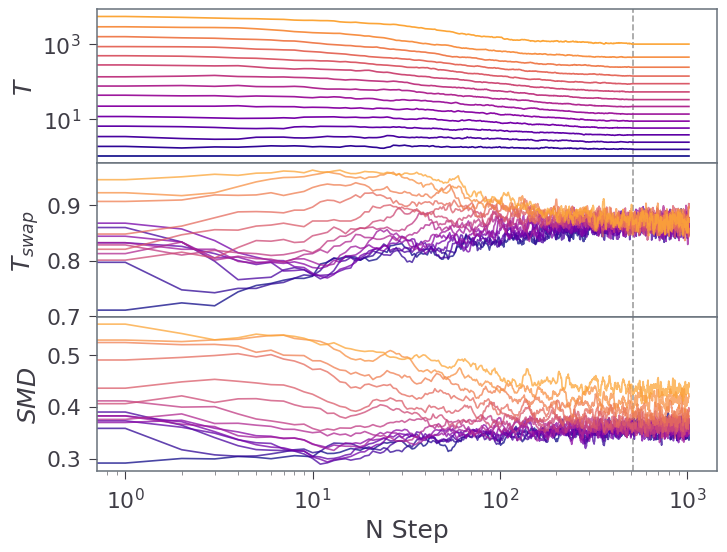

In [12]:
plot_ratios(sampler, setup)

#### The Evidence
We can retrieve the results with the *get_evidence_ti()* function. We discard the unstable samples with the keyword discard, for this showcase we will use half the chain.
This function performs thermodynamic integration as described in the reddemcee paper (*link*), and returns (evidence, error).

You can also use *get_evidence_ti()* to compare with the stepping-stones algorithm (Xie et al. 2011).

We also have *get_evidence_hybrid()* as a method.
For this problem the evidence is analitically tractable (see Lartillot&Phillipe 2007):
$$Z = -1.75$$

In [13]:
rounder = 4
Z0, Zerr0 = sampler.get_evidence_ti(discard=burnin)
Z1, Zerr1 = sampler.get_evidence_ss(discard=burnin)
Z2, Zerr2 = sampler.get_evidence_hybrid(discard=burnin)

print(f'Evidence TI: {np.round(Z0,rounder)} +- {np.round(Zerr0,rounder)}')
print(f'Evidence SS: {np.round(Z1,rounder)} +- {np.round(Zerr1,rounder)}')
print(f'Evidence Hy: {np.round(Z2,rounder)} +- {np.round(Zerr2,rounder)}')

Evidence TI: -1.7634 +- 0.0316
Evidence SS: -1.7499 +- 0.0093
Evidence Hy: -1.7618 +- 0.036


A very accurate result considering the length of the chain! Furthermore, we can take a peek at how the temperatures adapted during the run (horizontal color lines) and where they ended (solid circles). The shaded area corresponds to the classic integration method, which gives some insight on what is being calculated:

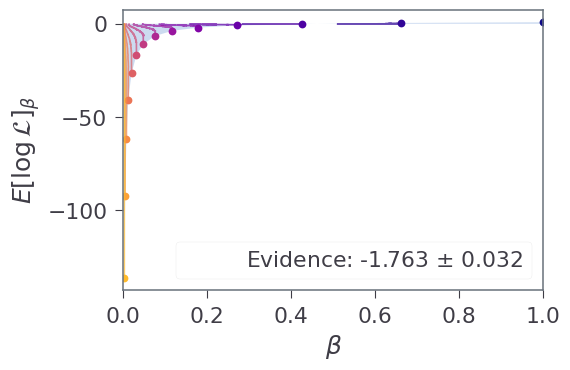

In [15]:
drop_hot_n = 2

likes = sampler.get_log_like()
betas = sampler.get_betas()[:-drop_hot_n, :]

logls = likes.mean(axis=2)[:-drop_hot_n, :]
ntemps_prime, nsweeps_prime = betas.shape

L = np.cumsum(logls, axis=1)/nsweeps_prime

cmap = colormaps['plasma']
colors = cmap(np.linspace(0, 0.85, ntemps_prime))

xaxis_la = r'$\beta$'
yaxis_la = r'$E[\log \mathcal{L}]_\beta$'
my_text = rf'Evidence: {Z0:.3f} $\pm$ {Zerr0:.3f}'

if True:
    fig, ax = pl.subplots(figsize=(6, 4))
    for ti in range(ntemps_prime):
        bet = betas[ti]
        ax.plot(bet, L[ti],
                c=colors[ti],
                alpha=0.7)
        
        ax.plot(bet[-1], L[ti, -1],
                c=colors[ti],
                marker='o')

    ylims = ax.get_ylim()
        
    betas0 = [x[-1] for x in betas]
    ax.fill_between(betas0, L[:, -1],
                        y2=0,
                        #color='w',
                        alpha=0.25)
        
    ax.set_ylim(ylims)
if True:
    ax.scatter([], [], alpha=0, label=my_text)
    pl.legend(loc=4)
    ax.set_xlabel(xaxis_la)
    ax.set_ylabel(yaxis_la)
        
    ax.set_xlim([0, 1])
    pl.tight_layout()
